
---
date: "2026-10-24"
date-modified: last-modified
format:
  html:
    toc: true
---


# Optimization

**Prerequisites:** [Local Extrema and the Mean Value Theorem](mean-value-theorem.ipynb#thm-fermat) · [Semicontinuity and the Extreme Value Theorem](semicontinuity-and-extreme-value-theorem.ipynb#cor-evt) · [Convexity, Inflection Points, and Curve Sketching](convexity-and-curve-sketching.ipynb)

## 1\. The Method

::: {#thm-closed-interval-method}
## Extrema on a Closed Interval

Let $f : [a, b] \to \mathbb{R}$ be continuous. Then $f$ attains its maximum and minimum, and each is attained at one of the following candidates:

1. the endpoints $a, b$;
2. **critical points**: interior points where $f'$ exists and equals $0$;
3. **singular points**: interior points where $f$ is not differentiable.

Comparing the values of $f$ at the candidates gives the extrema.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-closed-interval-method
The extrema exist by the [extreme value theorem](semicontinuity-and-extreme-value-theorem.ipynb#cor-evt). An extremum at an interior point where $f$ is differentiable is a local extremum, so $f' = 0$ there by [Fermat](mean-value-theorem.ipynb#thm-fermat). $\blacksquare$
:::

On open or unbounded intervals, replace step 1 by the limits of $f$ at the ends; an extremum may then fail to exist. The first step in an applied problem is to write the function and its domain precisely.

## 2\. Examples

::: {#exm-island}
## Shortest Travel Time

A point $B$ is $3$ km from a straight coast; the nearest coastal point is $5$ km from $A$, also on the coast. One drives $x$ km along the coast at $40$ km/h and then goes by boat at $20$ km/h straight to $B$. The time is
$$t(x) = \frac{x}{40} + \frac{\sqrt{9 + (5 - x)^2}}{20}, \qquad 0 \le x \le 5 .$$
$t$ is differentiable on $(0, 5)$, and $t'(x) = \frac{1}{40} - \frac{5 - x}{20\sqrt{9 + (5 - x)^2}} = 0$ gives $\sqrt{9 + (5-x)^2} = 2(5 - x)$, so $(5 - x)^2 = 3$ and $x = 5 - \sqrt3 \approx 3.268$. Comparing
$$t(0) = \tfrac{\sqrt{34}}{20} \approx 0.2915, \qquad t(5 - \sqrt3) = \tfrac{5 + 3\sqrt3}{40} \approx 0.2549, \qquad t(5) = 0.275,$$
the minimum is at $x = 5 - \sqrt3$ km. (At the optimum the boat's path makes an angle $\theta$ with the coast with $\cos\theta = \frac{5-x}{2(5-x)} = \frac12$, i.e. $\cos\theta = \frac{v_{\text{boat}}}{v_{\text{car}}}$.)
:::

::: {#exm-nearest-point}
## Nearest Point on a Curve, Three Ways

Find the points of $y^2 = x^3$ nearest to $(4, 0)$. Minimize the squared distance.

1. *As a function of $x$.* The curve consists of $y = \pm x^{3/2}$, $x \ge 0$; by symmetry use the upper branch: $D(x) = (x - 4)^2 + x^3$ on $[0, \infty)$, $D(x) \to \infty$ as $x \to \infty$. $D'(x) = 3x^2 + 2x - 8 = (3x - 4)(x + 2)$, so the only critical point is $x = \frac43$, with $D(\frac43) = \frac{256}{27} < D(0) = 16$. The nearest points are $\big(\frac43, \pm\frac{8}{3\sqrt3}\big)$, at distance $\frac{16}{3\sqrt3}$.
2. *As a function of $y$.* $E(y) = (y^{2/3} - 4)^2 + y^2$ on $\mathbb{R}$. Now $y = 0$ is a **singular point** ($E$ is not differentiable there) and must be checked separately: $E(0) = 16$. Elsewhere $E'(y) = 0$ gives $y^{2/3} = \frac43$, the same points.
3. *Parametrically.* $x = t^2$, $y = t^3$: $F(t) = (t^2 - 4)^2 + t^6$, $F'(t) = 2t(3t^2 - 4)(t^2 + 2)$, critical points $t = 0$ and $t^2 = \frac43$. Here $(0,0)$ appears as an interior **critical point**, a local maximum ($F''(0) = -16$).

The same point $(0, 0)$ is an endpoint, a singular point or a critical point depending on the formulation, but the answer is the same.
:::

::: {#exm-fuel}
## Best Fuel Economy

If a car at constant speed $v$ burns $p(v)$ litres per hour, it burns $q(v) = p(v)/v$ litres per kilometre. $q'(v) = \frac{vp'(v) - p(v)}{v^2} = 0$ means $p'(v) = \frac{p(v)}{v}$: the tangent to the graph of $p$ passes through the origin. For $p(v) = \frac{(v - 50)^2}{100} + 5$, $vp' - p = \frac{v^2 - 3000}{100}$, so the best speed is $v = \sqrt{3000} \approx 54.8$ km/h, faster than the speed $50$ that minimizes consumption per hour.
:::

::: {#exm-marginal-cost}
## Marginal Cost and Revenue

Let $C(q)$ be the cost and $R(q)$ the revenue of producing and selling $q$ units, both differentiable. If the profit $P = R - C$ has an interior maximum at $q_0$, then $R'(q_0) = C'(q_0)$: **marginal revenue equals marginal cost** ($C'(q_0) \approx C(q_0 + 1) - C(q_0)$ is the cost of one more unit). With the **average cost** $a(q) = C(q)/q$, $C' = a + q a'$, so $a'(q) = \frac{C'(q) - a(q)}{q}$: the average cost is minimal where it equals the marginal cost.
:::

numerical minimizer: 3.2675 | 5 - sqrt(3) = 3.267949192431123 | t_min = 0.2549038105676658 = 0.2549038105676658


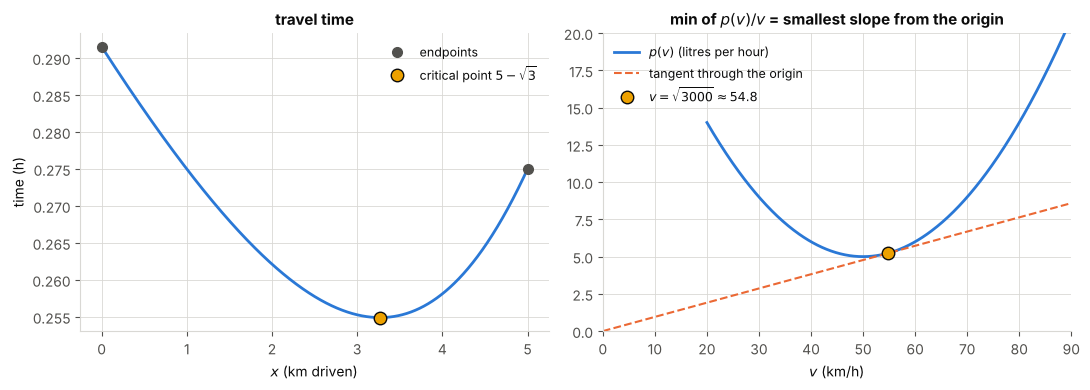

In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})

t = lambda x: x / 40 + np.sqrt(9 + (5 - x) ** 2) / 20
x = np.linspace(0, 5, 2001)
xs = 5 - np.sqrt(3)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax.plot(x, t(x), color=BLUE, lw=2)
ax.plot([0, 5], [t(0), t(5)], "o", color=MUTED, ms=7, label="endpoints")
ax.plot(xs, t(xs), "o", color=YELLOW, mec=INK, ms=9, label=r"critical point $5 - \sqrt{3}$")
ax.set_xlabel("$x$ (km driven)"); ax.set_ylabel("time (h)"); ax.legend(fontsize=9)
ax.set_title("travel time")
print("numerical minimizer:", x[np.argmin(t(x))], "| 5 - sqrt(3) =", xs, "| t_min =", t(xs), "=", (5 + 3*np.sqrt(3)) / 40)

p = lambda v: (v - 50) ** 2 / 100 + 5
v = np.linspace(20, 90, 400)
vs = np.sqrt(3000)
ax2.plot(v, p(v), color=BLUE, lw=2, label="$p(v)$ (litres per hour)")
ax2.plot([0, 90], [0, p(vs) / vs * 90], color=ORANGE, lw=1.5, ls="--", label="tangent through the origin")
ax2.plot(vs, p(vs), "o", color=YELLOW, mec=INK, ms=9, label=rf"$v = \sqrt{{3000}} \approx {vs:.1f}$")
ax2.set_xlim(0, 90); ax2.set_ylim(0, 20); ax2.set_xlabel("$v$ (km/h)"); ax2.legend(fontsize=9)
ax2.set_title("min of $p(v)/v$ = smallest slope from the origin")
plt.tight_layout(); plt.show()